# Compare MARRMoT models and select the best one

Reads the results written by `find_best_model.py` (`performance/<gauge>/`),
ranks every model by a performance metric of your choice, and re-runs the
selected model's best realization to plot it against the observed flow.

1. Run `find_best_model.py` for a gauge first.
2. Edit the **Settings** cell below and run all cells.

Ranking direction is handled per metric: NSE, KGE, log_NSE, pdi_*, r and
correlation are maximized; PBIAS and the mean annual peak-flow difference are
best at 0; alpha and beta are best at 1.

In [ ]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import find_best_model as fbm
import marrmot_models as marrmot

warnings.filterwarnings("ignore", category=RuntimeWarning)  # overflow in poor parameter sets

## Settings

In [ ]:
GAUGE = "02249500"
METRIC = "pdi_ave"         # NSE, KGE, log_NSE, pdi_ave, pdi_ave2, pdi_ave3, pdi_low, pdi_high, PBIAS,
                       # KGE_r, KGE_alpha, KGE_beta, correlation, mean_annual_peak_flow_diff
                       # (pdi_ave2/pdi_ave3 only exist in runs made after they were added)
TOP_N = 10             # models shown in the ranking and distribution plot
CONSTRAINTS = {}       # a realization only counts if it meets all of these, e.g.
                       # {"PBIAS": (-15, 15), "NSE": (0, None)}  -> (min, max), None = no bound
SELECTED_MODEL = None  # None = the top-ranked model; or a model number to inspect another one
N_COMPARE = 3          # top models overlaid in the hydrograph plots (max 3)

## Load the results

In [ ]:
if GAUGE is None:
    runs = sorted(fbm.PERFORMANCE_DIR.glob("*/run_info.json"), key=lambda p: p.stat().st_mtime)
    if not runs:
        raise FileNotFoundError(f"No results in {fbm.PERFORMANCE_DIR}; run find_best_model.py first")
    GAUGE = runs[-1].parent.name

out_dir = fbm.PERFORMANCE_DIR / GAUGE
run_info = json.loads((out_dir / "run_info.json").read_text())

tables = {int(p.name[6:8]): pd.read_parquet(p) for p in sorted(out_dir.glob("model_*.parquet"))}
names = {m: marrmot.MODEL_REGISTRY[m]["name"] for m in tables}

ALL_METRICS = ["NSE", "KGE", "KGE_r", "KGE_alpha", "KGE_beta", "PBIAS", "correlation",
               "mean_annual_peak_flow_diff", "pdi_ave", "pdi_ave2", "pdi_ave3",
               "pdi_low", "pdi_high", "log_NSE"]
# Older runs were scored before some metrics existed: only use the ones every table has
METRICS = [k for k in ALL_METRICS if all(k in t.columns for t in tables.values())]
not_in_run = [k for k in ALL_METRICS if k not in METRICS]


def require_metrics(*keys):
    missing = [k for k in keys if k not in METRICS]
    if missing:
        raise ValueError(f"{missing} not in the results of gauge {GAUGE}: this run was made before "
                         f"they were added; rerun find_best_model.py for it. Available: {METRICS}")

# One row per successful realization of every model, metrics only
# (parameters differ between models, so they stay in `tables`).
results = pd.concat(
    [t.loc[t["error"].isna(), METRICS].reset_index().assign(model=m, name=names[m])
     for m, t in tables.items()],
    ignore_index=True,
)

print(f"Gauge {GAUGE}: {run_info['start_year']}-{run_info['end_year']}, "
      f"{run_info['n_realizations']} realizations per model, ET = {run_info['et_method']}")
print(f"{len(tables)} models with results, {len(results)} successful realizations")
if not_in_run:
    print(f"Metrics not in this run (made before they were added): {', '.join(not_in_run)}")
if run_info["models_removed"]:
    print("Removed (every realization failed):",
          ", ".join(f"{m} {marrmot.MODEL_REGISTRY[int(m)]['name']}" for m in run_info["models_removed"]))

Gauge 02249500: 2015-2025, 50 realizations per model, ET = Turc
44 models with results, 2151 successful realizations
Removed (every realization failed): 23 Large-scale catchment water and salt balance model (LASCAM), 42 HYCYMODEL


## Rank the models

In [4]:
TARGETS = {"PBIAS": 0.0, "mean_annual_peak_flow_diff": 0.0, "KGE_alpha": 1.0, "KGE_beta": 1.0}
KEY_METRICS = ["NSE", "KGE", "log_NSE", "pdi_ave", "pdi_low", "PBIAS"]


def goodness(metric, values):
    # Higher is better for every metric: distance to the target for PBIAS/alpha/beta...
    if metric in TARGETS:
        return -(values - TARGETS[metric]).abs()
    return values


def apply_constraints(df, constraints):
    keep = pd.Series(True, index=df.index)
    for col, (lo, hi) in constraints.items():
        if lo is not None:
            keep &= df[col] >= lo
        if hi is not None:
            keep &= df[col] <= hi
    return df[keep]


def rank_models(metric, constraints=None):
    # One row per model: its best realization under `metric` (and that
    # realization's other key metrics), the median over all valid realizations,
    # and how many realizations met the constraints.
    require_metrics(metric, *(constraints or {}))
    df = apply_constraints(results, constraints or {}).dropna(subset=[metric])
    df = df.assign(score=goodness(metric, df[metric]))
    best = df.loc[df.groupby("model")["score"].idxmax()].set_index("model")
    stats = df.groupby("model")[metric].agg(["median", "size"])
    ranking = best.join(stats).sort_values("score", ascending=False)
    ranking.insert(0, "rank", np.arange(1, len(ranking) + 1))
    ranking = ranking.rename(columns={"median": f"median_{metric}", "size": "n_valid"})
    others = [k for k in KEY_METRICS if k != metric]
    return ranking[["rank", "name", "realization", metric, f"median_{metric}", "n_valid"] + others]


ranking = rank_models(METRIC, CONSTRAINTS)
if ranking.empty:
    raise ValueError("No realization satisfies CONSTRAINTS; relax them")

best_model = int(SELECTED_MODEL or ranking.index[0])
print(f"Best model by {METRIC}"
      + (f" (constraints: {CONSTRAINTS})" if CONSTRAINTS else "")
      + f": {ranking.index[0]} {ranking.iloc[0]['name']}  ->  {METRIC} = {ranking.iloc[0][METRIC]:.3f}")
ranking.head(TOP_N).style.format(precision=3).hide(axis="columns", subset=["realization"])

Best model by pdi_ave: 7 GR4J  ->  pdi_ave = 0.593


,rank,name,pdi_ave,median_pdi_ave,n_valid,NSE,KGE,log_NSE,pdi_low,PBIAS
model,,,,,,,,,,
7,1,GR4J,0.593,-0.484,50,0.059,0.157,-0.003,0.561,-8.832
13,2,Hillslope model,0.560,-0.729,46,-0.125,0.428,0.064,0.350,5.203
5,3,IHACRES,0.505,-0.899,50,-0.174,-0.384,-0.843,0.899,-28.100
40,4,SMAR,0.479,-0.661,50,-0.193,-0.442,-0.862,0.490,-26.905
31,5,MOPEX-3,0.471,-1.775,50,0.127,0.093,0.321,0.821,-6.659
24,6,MOPEX-1,0.459,-1.782,50,0.035,-0.026,0.131,0.359,-26.836
34,7,FLEX-IS,0.405,-0.714,50,0.216,0.295,0.280,0.824,11.548
39,8,Midlands Catchment Runoff Model (MCRM),0.365,0.032,50,0.092,0.072,0.004,0.166,-16.637
30,9,MOPEX-2,0.339,-1.765,50,-0.078,-0.279,-0.524,0.669,-22.650


### Spread of the metric within each model

A model whose *best* realization barely beats the others but whose bulk is
much worse is harder to calibrate than one that is good across the parameter
space. Gray boxes are all valid realizations; the blue dot is the best one.
The axis is clipped to the 5th-100th percentile, so very poor realizations
(NSE of -1000 and so on) fall off the left edge.

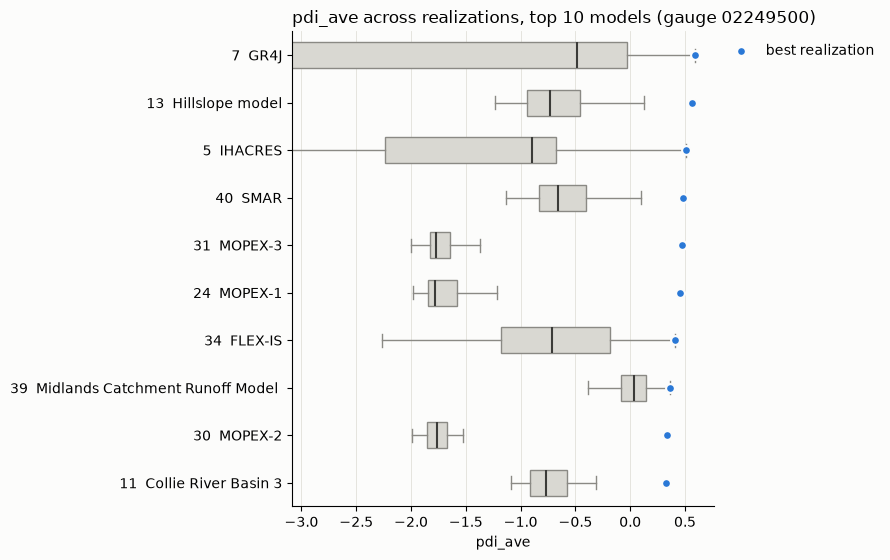

In [5]:
GRID, SURFACE, INK = "#e1e0d9", "#fcfcfb", "#3b3b38"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]  # categorical slots 1-3, in fixed order

top = ranking.head(TOP_N)
valid = apply_constraints(results, CONSTRAINTS).dropna(subset=[METRIC])
data = [valid.loc[valid["model"] == m, METRIC].to_numpy() for m in top.index]

fig, ax = plt.subplots(figsize=(9, 0.45 * len(top) + 1.2))
pos = np.arange(len(top))[::-1]  # rank 1 at the top
ax.boxplot(data, positions=pos, orientation="horizontal", widths=0.55, showfliers=False,
           patch_artist=True, boxprops=dict(facecolor="#d9d8d2", edgecolor="#8a8984", lw=1),
           medianprops=dict(color=INK, lw=1.5), whiskerprops=dict(color="#8a8984"),
           capprops=dict(color="#8a8984"))
ax.scatter(top[METRIC], pos, s=40, color=SERIES[0], edgecolor=SURFACE, lw=1.5, zorder=3,
           label=f"best realization")
if METRIC in TARGETS:
    ax.axvline(TARGETS[METRIC], color=INK, ls="--", lw=0.8)

all_vals = np.concatenate(data)
lo, hi = np.nanpercentile(all_vals, [5, 100])
lo = min(lo, top[METRIC].min())
pad = 0.05 * (hi - lo or 1)
ax.set_xlim(lo - pad, hi + pad)
ax.set_yticks(pos, [f"{m}  {top.loc[m, 'name'][:32]}" for m in top.index])
ax.set_xlabel(METRIC)
ax.set_title(f"{METRIC} across realizations, top {len(top)} models (gauge {GAUGE})", loc="left")
ax.grid(axis="x", color=GRID, lw=0.6)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
ax.set_facecolor(SURFACE)
fig.patch.set_facecolor(SURFACE)
fig.tight_layout()
plt.show()

### Best value each model reaches on each metric

Each column is ranked independently (the best NSE and the best KGE of a model
usually come from *different* realizations). Darker = better rank within
that column. Useful to see whether a model is good across the board or only
on one metric.

In [ ]:
best_by_metric = pd.DataFrame({
    k: valid.assign(score=goodness(k, valid[k])).groupby("model")
           .apply(lambda g: g.loc[g["score"].idxmax(), k] if g["score"].notna().any() else np.nan,
                  include_groups=False)
    for k in KEY_METRICS
}).loc[top.index]
best_by_metric.insert(0, "name", top["name"])

col_ranks = pd.DataFrame({k: goodness(k, best_by_metric[k]).rank() for k in KEY_METRICS})
(best_by_metric.style.format(precision=3, subset=KEY_METRICS)
 .background_gradient(cmap="Blues", gmap=col_ranks, subset=KEY_METRICS, axis=None))

,name,NSE,KGE,log_NSE,pdi_ave,pdi_low,PBIAS
model,,,,,,,
7,GR4J,0.085,0.318,-0.003,0.593,0.798,0.282
13,Hillslope model,0.179,0.455,0.064,0.560,0.575,-1.987
5,IHACRES,-0.059,-0.113,-0.047,0.505,0.899,7.840
40,SMAR,-0.021,-0.038,-0.190,0.479,0.691,-10.911
31,MOPEX-3,0.127,0.223,0.321,0.471,0.821,-6.659
24,MOPEX-1,0.035,-0.022,0.131,0.459,0.641,-26.836
34,FLEX-IS,0.216,0.369,0.280,0.405,0.840,8.348
39,Midlands Catchment Runoff Model (MCRM),0.129,0.331,0.004,0.365,0.812,-1.056
30,MOPEX-2,-0.075,0.065,-0.100,0.339,0.669,-22.650


## Selected model

In [ ]:
if best_model not in ranking.index:
    raise ValueError(f"Model {best_model} has no realization meeting CONSTRAINTS (or no results)")

info = marrmot.MODEL_REGISTRY[best_model]
realization = int(ranking.loc[best_model, "realization"])
best_params = tables[best_model].loc[realization, info["param_names"]]
best_metrics = tables[best_model].loc[realization, METRICS]

print(f"Model {best_model}: {info['name']}  ({info['marrmot_file']}), "
      f"rank {ranking.loc[best_model, 'rank']} of {len(ranking)}")
print(f"Best realization #{realization} by {METRIC}"
      + (f" with constraints {CONSTRAINTS}" if CONSTRAINTS else ""))
display(pd.DataFrame({"value": best_params.to_numpy(), "unit": [u.split(" (")[0] for u in info["param_units"]]},
                     index=info["param_names"]))
display(best_metrics.to_frame("value"))

Model 7: GR4J  (m_07_gr4j_4p_2s), rank 1 of 44
Best realization #9 by pdi_ave


,value,unit
x1,1892.495017,mm
x2,-0.242562,mm/d
x3,274.407082,mm
x4,6.681050,d


,value
NSE,0.058975
KGE,0.157218
r,0.318095
alpha,0.512673
beta,0.911683
PBIAS,-8.831737
correlation,0.318095
mean_annual_peak_flow_diff,-14.361899
pdi_ave,0.592843
pdi_low,0.560906


### Re-run and plot the best realizations

The forcing is rebuilt from `data/` with the same settings as the search
(`run_info.json`), and each simulation is checked against the stored metric.
The selected model plus the next-ranked ones (up to `N_COMPARE`) are overlaid.

In [ ]:
forcing = fbm.prepare_data(GAUGE, run_info["start_year"], run_info["end_year"],
                           run_info["warmup_years"], run_info["et_method"],
                           skip_snow=not run_info.get("temperature_available", True),
                           # runs made before AORC support used NASA POWER rain
                           precip_source=run_info.get("precip_source", "nasa"),
                           nasa_sampling=run_info.get("nasa_sampling", "point"))


def simulate_realization(model, realization):
    info = marrmot.MODEL_REGISTRY[model]
    params = tables[model].loc[realization, info["param_names"]].to_dict()
    S0 = np.full(info["n_stores"], fbm.INITIAL_STORAGE)
    result = marrmot.simulate(model, forcing["P"], forcing["Ep"], params, S0=S0, dt=1.0,
                              T=forcing["T"], t=forcing["t"])
    Q = np.maximum(np.asarray(result["Q"], dtype=float)[forcing["eval_mask"]], fbm.Q_FLOOR)
    return pd.DataFrame({"Q": Q, "Qobs": forcing["Qobs"]}, index=forcing["dates"])


compare = [best_model] + [m for m in ranking.index if m != best_model][:max(0, min(N_COMPARE, 3) - 1)]
sims = {}
for m in compare:
    sims[m] = simulate_realization(m, int(ranking.loc[m, "realization"]))
    recomputed = fbm.compute_metrics(sims[m])[METRIC]
    stored = ranking.loc[m, METRIC]
    status = "matches" if np.isclose(recomputed, stored, rtol=1e-6, equal_nan=True) else "DIFFERS from"
    print(f"Model {m:2d}: re-simulated {METRIC} = {recomputed:.4f} {status} stored {stored:.4f}")

Using existing data\usgs_02249500_daily.parquet
Using existing data\usgs_02249500_forcing.parquet
Drainage area: 32.6 km2
Simulation:    2014-01-01 to 2025-12-31 (4383 days, 1 warm-up year(s))
Evaluation:    2015-01-01 to 2025-12-31 (4018 days with observed flow)
Model  7: re-simulated pdi_ave = 0.5928 matches stored 0.5928
Model 13: re-simulated pdi_ave = 0.5596 matches stored 0.5596
Model  5: re-simulated pdi_ave = 0.4265 DIFFERS from stored 0.5050


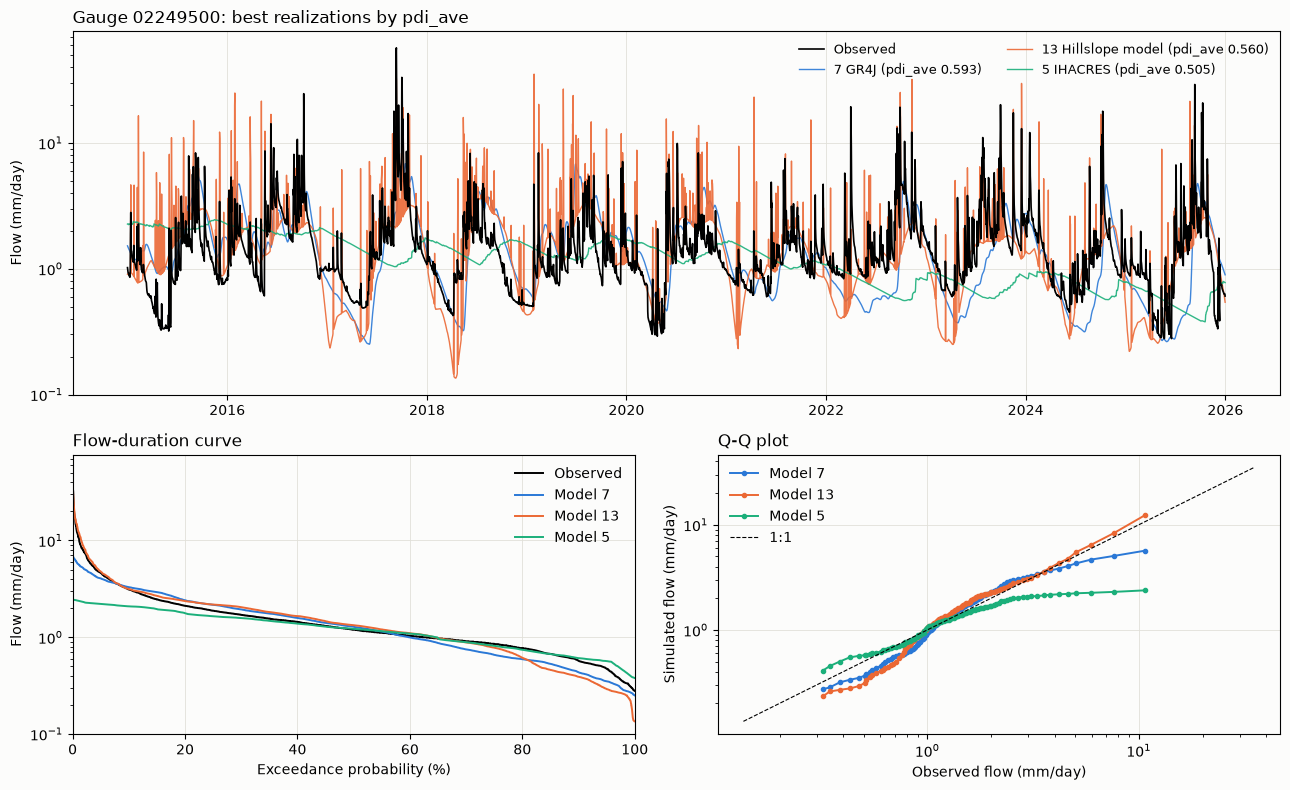

In [ ]:
obs = forcing["Qobs"]
obs_pos = obs[np.isfinite(obs) & (obs > 0)]

fig = plt.figure(figsize=(13, 8))
gs = fig.add_gridspec(2, 2, height_ratios=[1.3, 1])
ax_ts, ax_fdc, ax_qq = fig.add_subplot(gs[0, :]), fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[1, 1])


def label(m):
    return f"{m} {marrmot.MODEL_REGISTRY[m]['name'][:28]} ({METRIC} {ranking.loc[m, METRIC]:.3f})"


def fdc(q):
    q = np.sort(q[np.isfinite(q)])[::-1]
    return 100 * np.arange(1, len(q) + 1) / (len(q) + 1), q


# Time series
ax_ts.plot(forcing["dates"], obs, color="k", lw=1.2, label="Observed", zorder=3)
for color, m in zip(SERIES, compare):
    ax_ts.plot(sims[m].index, sims[m]["Q"], color=color, lw=1.0, alpha=0.9, label=label(m))
ax_ts.set_yscale("log")
ax_ts.set_ylabel("Flow (mm/day)")
ax_ts.set_title(f"Gauge {GAUGE}: best realizations by {METRIC}", loc="left")
ax_ts.legend(frameon=False, ncol=2, fontsize=9)

# Flow-duration curves
ax_fdc.plot(*fdc(obs), color="k", lw=1.4, label="Observed")
for color, m in zip(SERIES, compare):
    ax_fdc.plot(*fdc(sims[m]["Q"].to_numpy()), color=color, lw=1.4, label=f"Model {m}")
ax_fdc.set_yscale("log")
ax_fdc.set_xlim(0, 100)
ax_fdc.set_xlabel("Exceedance probability (%)")
ax_fdc.set_ylabel("Flow (mm/day)")
ax_fdc.set_title("Flow-duration curve", loc="left")
ax_fdc.legend(frameon=False)

# Q-Q plot
probs = np.linspace(0.01, 0.99, 99)
q_obs = np.quantile(obs_pos, probs)
for color, m in zip(SERIES, compare):
    ax_qq.plot(q_obs, np.quantile(sims[m]["Q"], probs), color=color, lw=1.4,
               marker="o", ms=3, label=f"Model {m}")
lims = [min(q_obs.min(), *(sims[m]["Q"].min() for m in compare)),
        max(q_obs.max(), *(sims[m]["Q"].max() for m in compare))]
ax_qq.plot(lims, lims, color="k", ls="--", lw=0.8, label="1:1")
ax_qq.set_xscale("log")
ax_qq.set_yscale("log")
ax_qq.set_xlabel("Observed flow (mm/day)")
ax_qq.set_ylabel("Simulated flow (mm/day)")
ax_qq.set_title("Q-Q plot", loc="left")
ax_qq.legend(frameon=False)

for ax in (ax_ts, ax_fdc, ax_qq):
    ax.grid(color=GRID, lw=0.6)
    ax.set_facecolor(SURFACE)
fig.patch.set_facecolor(SURFACE)
fig.tight_layout()
plt.show()

## Save the selection

Writes the selected model, its best parameter set and its metrics to
`performance/<gauge>/best_model_<METRIC>.json`, e.g. to use as a starting
point for a proper calibration (SCE-UA / NSGA-II in Example 5).

In [ ]:
selection = {
    "gauge": GAUGE,
    "metric": METRIC,
    "constraints": {k: list(v) for k, v in CONSTRAINTS.items()},
    "model": best_model,
    "name": info["name"],
    "realization": realization,
    "parameters": {k: float(v) for k, v in best_params.items()},
    "metrics": {k: (None if pd.isna(v) else float(v)) for k, v in best_metrics.items()},
    "run_info": run_info,
}
path = out_dir / f"best_model_{METRIC}.json"
path.write_text(json.dumps(selection, indent=2))
print(f"Saved {path.relative_to(fbm.HERE)}")

Saved performance\02249500\best_model_pdi_ave.json


## Compare up to 5 models

Pick a performance metric and, optionally, the models. Each model is shown
with its best realization under `COMPARE_METRIC` (respecting
`COMPARE_CONSTRAINTS`). Panels: time series (linear), time series (log),
flow-duration curve (log y) and Q-Q plot (log-log).

In [11]:
COMPARE_METRIC = "NSE"             # any metric from the ranking (NSE, KGE, log_NSE, pdi_low, PBIAS, ...)
COMPARE_MODELS = None              # None = top 5 by COMPARE_METRIC; or up to 5 model numbers, e.g. [7, 11, 25]
COMPARE_CONSTRAINTS = CONSTRAINTS  # same constraints as above; set to {} to ignore them here

,rank,name,realization,NSE,median_NSE,n_valid,KGE,log_NSE,pdi_ave,pdi_low,PBIAS
model,,,,,,,,,,,
34,1,FLEX-IS,30,0.216,-0.336,50,0.295,0.280,0.405,0.824,11.548
28,2,Xinanjiang model,46,0.186,-1.753,49,0.336,-1.060,-0.038,-0.469,-24.848
11,3,Collie River Basin 3,34,0.184,-0.224,50,0.409,-6.826,-0.313,-0.929,-11.484
13,4,Hillslope model,33,0.179,-0.164,46,0.263,-0.521,0.122,-0.359,-24.054
9,5,Susannah Brook model v1-5,44,0.177,-0.065,50,0.241,-27.748,-0.513,-1.000,8.109


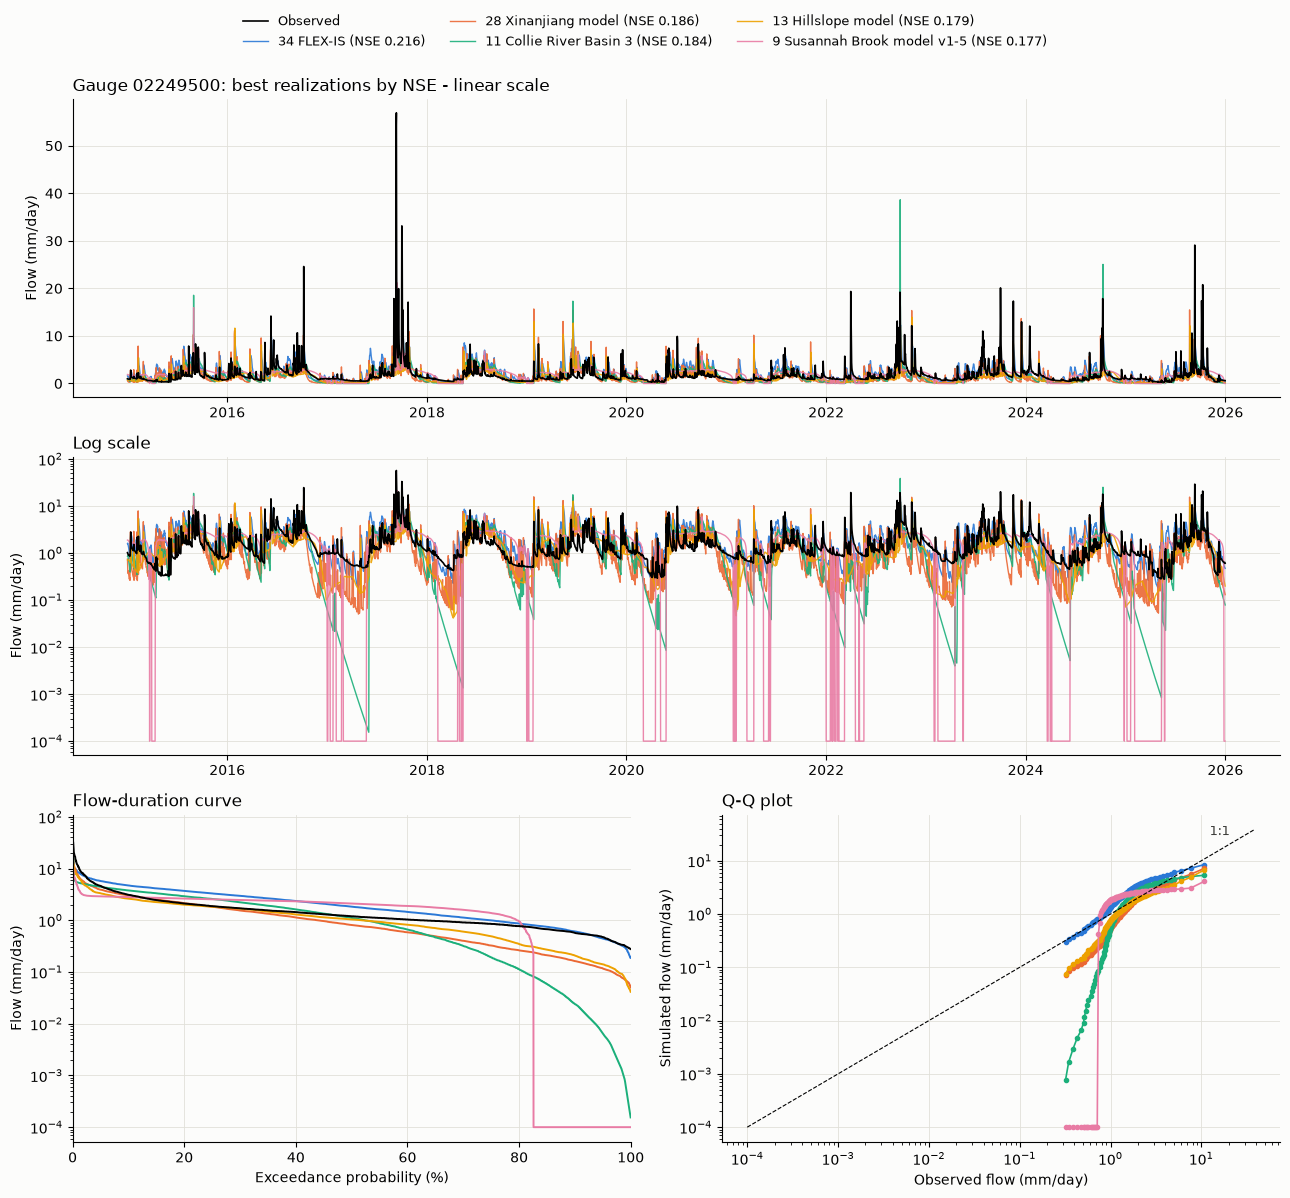

In [12]:
SERIES_5 = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]  # categorical slots 1-5, fixed order

cmp_ranking = rank_models(COMPARE_METRIC, COMPARE_CONSTRAINTS)
cmp_models = [int(m) for m in COMPARE_MODELS] if COMPARE_MODELS else list(cmp_ranking.index[:5])
if not 1 <= len(cmp_models) <= 5:
    raise ValueError("Compare between 1 and 5 models")
missing = [m for m in cmp_models if m not in cmp_ranking.index]
if missing:
    raise ValueError(f"No valid realization for model(s) {missing} under {COMPARE_METRIC}"
                     + (f" with constraints {COMPARE_CONSTRAINTS}" if COMPARE_CONSTRAINTS else ""))

cmp_sims = {m: simulate_realization(m, int(cmp_ranking.loc[m, "realization"])) for m in cmp_models}
display(cmp_ranking.loc[cmp_models].style.format(precision=3))

obs_series = pd.Series(forcing["Qobs"], index=forcing["dates"])
obs_pos = obs_series[obs_series > 0].dropna().to_numpy()
probs = np.linspace(0.01, 0.99, 99)
q_obs = np.quantile(obs_pos, probs)

fig = plt.figure(figsize=(13, 12))
gs = fig.add_gridspec(3, 2, height_ratios=[1, 1, 1.1])
ax_lin = fig.add_subplot(gs[0, :])
ax_log = fig.add_subplot(gs[1, :], sharex=ax_lin)
ax_fdc = fig.add_subplot(gs[2, 0])
ax_qq = fig.add_subplot(gs[2, 1])

for ax in (ax_lin, ax_log):
    ax.plot(obs_series.index, obs_series, color="k", lw=1.2, label="Observed", zorder=3)
ax_fdc.plot(*fdc(obs_series.to_numpy()), color="k", lw=1.4, zorder=3)

for color, m in zip(SERIES_5, cmp_models):
    q = cmp_sims[m]["Q"]
    name = f"{m} {marrmot.MODEL_REGISTRY[m]['name'][:28]} ({COMPARE_METRIC} {cmp_ranking.loc[m, COMPARE_METRIC]:.3f})"
    ax_lin.plot(q.index, q, color=color, lw=1.0, alpha=0.9, label=name)
    ax_log.plot(q.index, q, color=color, lw=1.0, alpha=0.9)
    ax_fdc.plot(*fdc(q.to_numpy()), color=color, lw=1.4)
    ax_qq.plot(q_obs, np.quantile(q, probs), color=color, lw=1.2, marker="o", ms=3)

lims = [min(q_obs.min(), *(cmp_sims[m]["Q"].min() for m in cmp_models)),
        max(q_obs.max(), *(cmp_sims[m]["Q"].max() for m in cmp_models))]
ax_qq.plot(lims, lims, color="k", ls="--", lw=0.8)
ax_qq.annotate("1:1", xy=(lims[1], lims[1]), xytext=(-18, -4), textcoords="offset points",
               color=INK, fontsize=9, ha="right")

ax_lin.set_ylabel("Flow (mm/day)")
ax_lin.set_title(f"Gauge {GAUGE}: best realizations by {COMPARE_METRIC} - linear scale", loc="left")
ax_log.set_yscale("log")
ax_log.set_ylabel("Flow (mm/day)")
ax_log.set_title("Log scale", loc="left")
ax_fdc.set_yscale("log")
ax_fdc.set_xlim(0, 100)
ax_fdc.set_xlabel("Exceedance probability (%)")
ax_fdc.set_ylabel("Flow (mm/day)")
ax_fdc.set_title("Flow-duration curve", loc="left")
ax_qq.set_xscale("log")
ax_qq.set_yscale("log")
ax_qq.set_xlabel("Observed flow (mm/day)")
ax_qq.set_ylabel("Simulated flow (mm/day)")
ax_qq.set_title("Q-Q plot", loc="left")

for ax in (ax_lin, ax_log, ax_fdc, ax_qq):
    ax.grid(color=GRID, lw=0.6)
    ax.set_facecolor(SURFACE)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)

# One legend for all four panels (same colors everywhere)
fig.legend(*ax_lin.get_legend_handles_labels(), loc="upper center", ncol=3, frameon=False,
           fontsize=9, bbox_to_anchor=(0.5, 1.0))
fig.patch.set_facecolor(SURFACE)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

## Best model per metric (interactive)

For each selected metric (up to 5), the best model and realization under that
metric, shown with the same four panels. Interactive (plotly): hover to read
values, drag to zoom (the two time-series panels zoom together), double-click
to reset, and click a legend entry to hide or show that line in every panel.
If the same model and realization wins several metrics, it is drawn once and
labelled with all of them.

In [ ]:
BEST_BY_METRICS = ["NSE", "KGE", "log_NSE", "pdi_ave", "pdi_low"]  # up to 5, any of METRICS
BEST_BY_CONSTRAINTS = CONSTRAINTS                                  # set to {} to ignore them here

In [ ]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

unknown = [k for k in BEST_BY_METRICS if k not in ALL_METRICS]
if unknown:
    raise ValueError(f"Unknown metric(s) {unknown}; choose from {ALL_METRICS}")
require_metrics(*BEST_BY_METRICS)  # also in this gauge's results?
if not 1 <= len(BEST_BY_METRICS) <= 5:
    raise ValueError("Select between 1 and 5 metrics")

# Winner (model + realization) for each metric
winners = []
for metric in BEST_BY_METRICS:
    r = rank_models(metric, BEST_BY_CONSTRAINTS)
    if r.empty:
        raise ValueError(f"No realization satisfies the constraints for {metric}")
    winners.append({"metric": metric, "model": int(r.index[0]), "name": r.iloc[0]["name"],
                    "realization": int(r.iloc[0]["realization"]), "value": r.iloc[0][metric]})
winners = pd.DataFrame(winners)

display(pd.concat(
    [winners.set_index("metric")[["model", "name", "realization"]],
     pd.DataFrame([tables[w.model].loc[w.realization, KEY_METRICS] for w in winners.itertuples()],
                  index=winners["metric"])],
    axis=1,
).style.format(precision=3))

# One line per distinct (model, realization); colors follow metric order
lines = []
for (m, real), grp in winners.groupby(["model", "realization"], sort=False):
    won = ", ".join(f"{k} {v:.3f}" for k, v in zip(grp["metric"], grp["value"]))
    lines.append({"model": m, "realization": real, "color": SERIES_5[len(lines)],
                  "label": f"{m} {grp['name'].iloc[0][:28]} - best {won}",
                  "sim": simulate_realization(m, real)["Q"]})

obs_series = pd.Series(forcing["Qobs"], index=forcing["dates"])
probs = np.linspace(0.01, 0.99, 99)
q_obs = np.quantile(obs_series[obs_series > 0].dropna(), probs)

fig = make_subplots(
    rows=3, cols=2,
    specs=[[{"colspan": 2}, None], [{"colspan": 2}, None], [{}, {}]],
    row_heights=[0.31, 0.31, 0.38], vertical_spacing=0.07, horizontal_spacing=0.08,
    subplot_titles=("Time series - linear scale", "Time series - log scale",
                    "Flow-duration curve", "Q-Q plot"),
)


def add_line(x, y, label, color, group, show_legend, row, col, hover, width=1.4, mode="lines"):
    fig.add_trace(go.Scatter(
        x=x, y=y, name=label, legendgroup=group, showlegend=show_legend, mode=mode,
        line=dict(color=color, width=width), marker=dict(size=5),
        hovertemplate=hover + f"<extra>{label.split(' - ')[0]}</extra>",
    ), row=row, col=col)


series = [{"label": "Observed", "color": "black", "q": obs_series, "group": "obs"}] + \
         [{"label": l["label"], "color": l["color"], "q": l["sim"], "group": f"{l['model']}-{l['realization']}"}
          for l in lines]

for s in series:
    q = s["q"]
    add_line(q.index, q, s["label"], s["color"], s["group"], True, 1, 1, "%{y:.3f} mm/day")
    add_line(q.index, q, s["label"], s["color"], s["group"], False, 2, 1, "%{y:.3f} mm/day")
    exceed, q_sorted = fdc(q.to_numpy())
    add_line(exceed, q_sorted, s["label"], s["color"], s["group"], False, 3, 1,
             "%{y:.3f} mm/day at %{x:.1f}% exceedance")
    if s["group"] != "obs":
        add_line(q_obs, np.quantile(q, probs), s["label"], s["color"], s["group"], False, 3, 2,
                 "obs %{x:.3f} → sim %{y:.3f} mm/day", mode="lines+markers", width=1.2)

lims = [min(q_obs.min(), *(l["sim"].min() for l in lines)),
        max(q_obs.max(), *(l["sim"].max() for l in lines))]
fig.add_trace(go.Scatter(x=lims, y=lims, mode="lines", name="1:1", showlegend=False,
                         line=dict(color=INK, width=1, dash="dash"), hoverinfo="skip"), row=3, col=2)

fig.update_xaxes(matches="x", row=2, col=1)  # the two time-series panels zoom together
fig.update_yaxes(title_text="Flow (mm/day)", row=1, col=1)
fig.update_yaxes(title_text="Flow (mm/day)", type="log", row=2, col=1)
fig.update_yaxes(title_text="Flow (mm/day)", type="log", row=3, col=1)
fig.update_xaxes(title_text="Exceedance probability (%)", range=[0, 100], row=3, col=1)
fig.update_xaxes(title_text="Observed flow (mm/day)", type="log", row=3, col=2)
fig.update_yaxes(title_text="Simulated flow (mm/day)", type="log", row=3, col=2)
fig.update_xaxes(showgrid=True, gridcolor=GRID, linecolor="#8a8984", zeroline=False)
fig.update_yaxes(showgrid=True, gridcolor=GRID, linecolor="#8a8984", zeroline=False)
fig.update_layout(
    title=dict(text=f"Gauge {GAUGE}: best model per metric"
                    + (f" (constraints {BEST_BY_CONSTRAINTS})" if BEST_BY_CONSTRAINTS else ""), x=0.01, y=0.99, yanchor="top"),
    height=1050, template="simple_white", plot_bgcolor=SURFACE, paper_bgcolor=SURFACE,
    hovermode="x unified", margin=dict(t=140, l=70, r=30, b=60),
    legend=dict(orientation="h", x=0, y=1.03, xanchor="left", yanchor="bottom", font=dict(size=11)),
)
fig.show()